# Exploratory Data Analysis (EDA)

## Block 1 — Understanding a Dataset

### Objective
Understand the structure, columns, and data types of a real-world dataset.

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("../datasets/titanic.csv")

In [3]:
print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


In [4]:
print("Dataset Shape: ", df.shape)
print("\nDataset coumns: ", df.columns.tolist())
print("\nDataset Info: ")
df.info()

Dataset Shape:  (891, 12)

Dataset coumns:  ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset Info: 
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [5]:
print("Dataset description: \n", df.describe())

Dataset description: 
        PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  


In [6]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})
missing_values = missing_values[missing_values["Missing Count"] > 0]

print(missing_values)

          Missing Count  Missing Percentage
Age                 177               19.87
Cabin               687               77.10
Embarked              2                0.22


In [7]:
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [8]:
print((df.isnull().mean() * 100).round(2))

PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
dtype: float64


In [9]:
print("Number of rows have a missing Age value :",df.isnull().sum()['Age'])
print("Number of rows have a missing Cabin value :", df.isnull().sum()["Cabin"])
print("Number of rows where both Age and Cabin are missing :", df[
    (df['Age'].isna()) & (df['Cabin'].isna())
    ][["Age", "Cabin"]].shape[0]
     )

Number of rows have a missing Age value : 177
Number of rows have a missing Cabin value : 687
Number of rows where both Age and Cabin are missing : 158


In [10]:
print(df.duplicated().sum())
print(df[df.duplicated()])

0
Empty DataFrame
Columns: [PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked]
Index: []


In [11]:
print(df["PassengerId"].isna().sum())
print(df["PassengerId"].duplicated().sum())
#One important distinction: PassengerId is unique in this dataset, but identifiers are not guaranteed to be unique in every dataset. Always verify this rather than assume it.

0
0


In [12]:
print(df["Embarked"].value_counts())
print(df["Embarked"].isnull().sum())

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64
2


In [13]:
#Find the number of unique values in the Sex column.
print(df['Sex'].unique().tolist())

#Display the number of passengers in each Sex category.
print(df['Sex'].value_counts())

#Check whether the Sex column contains any missing values.
print(df["Sex"].isnull().sum())

['male', 'female']
Sex
male      577
female    314
Name: count, dtype: int64
0


In [14]:
print("Mean of Age: ", df["Age"].mean().round(2))
print("Median of Age: ", df["Age"].median())
print("Minimum Age: ", df["Age"].min())
print("Maximum Age: ", df["Age"].max())
print("Standard Deviation: ", df["Age"].std().round(2))

Mean of Age:  29.7
Median of Age:  28.0
Minimum Age:  0.42
Maximum Age:  80.0
Standard Deviation:  14.53


In [15]:
print("Mean of Fare: ", df["Fare"].mean().round(2))
print("Median of Fare: ", df["Fare"].median())
print("Minimum Fare: ", df["Fare"].min())
print("Maximum Fare: ", df["Fare"].max())

Mean of Fare:  32.2
Median of Fare:  14.4542
Minimum Fare:  0.0
Maximum Fare:  512.3292


In [16]:
print("Survival Rate %: ", (df["Survived"].mean() * 100).round(2))

Survival Rate %:  38.38


In [17]:
print((df["Pclass"].value_counts(normalize = True) * 100).round(2))

Pclass
3    55.11
1    24.24
2    20.65
Name: proportion, dtype: float64


### Task A: Understand the categories

Using your existing `df` DataFrame, write code to:

1. Display the number of passengers in each `Pclass`.
2. Calculate the percentage of passengers in each class.

**Hint:** You've already used `value_counts()`. Think about how to convert counts into percentages.

### Task B: Investigate survival

Write code to:

3. Count survivors and non-survivors in each passenger class.
4. Calculate the survival percentage **within each passenger class**.

For example, the question we're trying to answer is:

*Of all passengers in first class, what percentage survived?*

We are not asking what percentage of all survivors belonged to first class. Those are two different calculations.

**Hint:** Think about the Pandas method that groups data by a column before calculating a statistic.

### Task C: Interpret the results

After running your code, answer:

* **Q1.** Which passenger class had the highest survival rate?
* **Q2.** Why is comparing survival percentages more useful than comparing survivor counts alone?
* **Q3.** If first-class passengers had a higher survival rate, does that prove that passenger class caused better survival outcomes? Why or why not?

In [18]:
print(df["Pclass"].value_counts())
print((df["Pclass"].value_counts(
    normalize = True
)*100).round(2))

Pclass
3    491
1    216
2    184
Name: count, dtype: int64
Pclass
3    55.11
1    24.24
2    20.65
Name: proportion, dtype: float64


In [19]:
print(df.groupby(
    "Pclass"
)["Survived"].value_counts())

Pclass  Survived
1       1           136
        0            80
2       0            97
        1            87
3       0           372
        1           119
Name: count, dtype: int64


In [20]:
print((df.groupby(
    "Pclass"
)["Survived"].value_counts(
    normalize = True
) * 100).round(2))

Pclass  Survived
1       1           62.96
        0           37.04
2       0           52.72
        1           47.28
3       0           75.76
        1           24.24
Name: proportion, dtype: float64


### Task A: Calculate the IQR boundaries

Independently write code to calculate:

1. Q1 (25th percentile) of `Fare`.
2. Q3 (75th percentile) of `Fare`.
3. IQR.
4. Lower bound.
5. Upper bound.

**Hint:** Pandas provides a method for calculating percentiles. You've already learned how to calculate the mean, median and standard deviation.

### Task B: Count potential outliers

Using the boundaries you calculated, write code to count:

* Fares below the lower bound.
* Fares above the upper bound.

### Task C: Interpret the results

After running your code, answer:

**Q1.** How many potential outliers exist above the upper bound?

**Q2.** Should we automatically remove these fares? Why or why not?

**Q3.** Why might the IQR method be useful when the data is right-skewed?


In [21]:
print(df["Fare"].describe())

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64


In [22]:
q1 = df['Fare'].quantile(0.25)
q3 = df['Fare'].quantile(0.75)
print("Q1 : ", q1, "\nQ3 : ", q3)
iqr = q3 - q1
print("IQR : ", iqr)
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)
print(f'Lower Bound : {lower_bound}')
print(f'Upper Bound : {upper_bound}')

Q1 :  7.9104 
Q3 :  31.0
IQR :  23.0896
Lower Bound : -26.724
Upper Bound : 65.6344


In [23]:
print("Count of Fares below lower bound : ", (df['Fare'] <  lower_bound).sum())
print("Count of Fares above upper bound : ", (df["Fare"] > upper_bound).sum())

Count of Fares below lower bound :  0
Count of Fares above upper bound :  116


In [24]:
removed_outliers_df = df[
    (df["Fare"] > lower_bound) & (df["Fare"] < upper_bound)
]
print(removed_outliers_df['PassengerId'].count())
print(removed_outliers_df["Fare"].std())

775
13.578085353787758


### Task A: Numerical correlation

Calculate the correlation matrix for these columns:

* `Age`
* `Fare`
* `Pclass`
* `Survived`

**Your task:** Write code to calculate their correlations.

Hint: Pandas has a method that calculates correlations between numerical columns.

One caution: `Pclass` is an ordinal category, and `Survived` is binary. Their numerical correlations can be useful for exploration, but they require careful interpretation.

### Task B: Survival by sex

Calculate the survival rate for each category in `Sex`.

For this dataset:

* `Survived = 1` means the passenger survived.
* `Survived = 0` means the passenger did not survive.

You want the **percentage who survived within each sex category**, not the percentage of all survivors who belong to each category.

### Task C: Interpret your findings

After running your code, answer these questions:

**Q1.** Which of the selected variables has the strongest positive correlation with `Survived`?

**Q2.** Which group—male or female passengers—had the higher survival rate?

**Q3.** If female passengers had a higher survival rate, does that prove being female caused survival? Why or why not?

**Q4.** Why might correlation alone be insufficient for analysing relationships between categorical variables?

In [25]:
print(df[["Age", "Fare", "Pclass", "Survived"]].corr().round(2))

           Age  Fare  Pclass  Survived
Age       1.00  0.10   -0.37     -0.08
Fare      0.10  1.00   -0.55      0.26
Pclass   -0.37 -0.55    1.00     -0.34
Survived -0.08  0.26   -0.34      1.00


In [26]:
print(df.groupby(
    "Sex"
)["Survived"].value_counts(
    normalize = True
).round(2) * 100)

Sex     Survived
female  1           74.0
        0           26.0
male    0           81.0
        1           19.0
Name: proportion, dtype: float64


In [27]:
print((df.groupby(
    "Sex"
)["Survived"].sum().div(
    df["Survived"].sum()
) * 100).round(2))

Sex
female    68.13
male      31.87
Name: Survived, dtype: float64


In [28]:
import matplotlib.pyplot as plt

### Task A — Histogram: Passenger Ages

Create a histogram using the `Age` column.

Your chart should:

* Display passenger age on the x-axis.
* Display the number of passengers on the y-axis.
* Have a descriptive title.
* Include readable axis labels.

**Questions to answer:**

1. Which age range appears most common?
2. Does the distribution appear symmetric or skewed?

*Hint:* Matplotlib provides a plotting function specifically for histograms.

### Task B — Box Plot: Ticket Fares

Create a box plot using the `Fare` column.

Your chart should have:

* A descriptive title.
* A readable label for the fare values.

**Questions to answer:**

1. Does the plot show potential outliers?
2. How does the plot help you understand the fare distribution?

*Hint:* You can create a box plot directly from the fare column.

### Task C — Bar Chart: Survival Rate by Sex

Create a bar chart comparing survival rates for male and female passengers.

Use the survival rates you learned to calculate in Block 6.

Your chart should:

* Have separate bars for males and females.
* Display survival percentages.
* Have a descriptive title and labelled axes.

**Questions to answer:**

1. Which group has the higher survival rate?
2. Why is a bar chart appropriate for this comparison?

---

## 4. What You Need to Remember for Machine Learning

You don't need to memorize every Matplotlib function.

Focus on choosing the right chart for the question:

| If you want to understand...                  | Start with... |
| --------------------------------------------- | ------------- |
| A numerical distribution                      | Histogram     |
| Spread and potential outliers                 | Box plot      |
| Differences between categories                | Bar chart     |
| Relationships between two numerical variables | Scatter plot  |

Scatter plots are useful too, but we'll prioritize the three charts above for this exercise.


| Chart        | Matplotlib function | Main purpose                                          | Titanic example                             |
| ------------ | ------------------- | ----------------------------------------------------- | ------------------------------------------- |
| Histogram    | `plt.hist()`        | Understand numerical distributions                    | How are passenger ages distributed?         |
| Box plot     | `plt.boxplot()`     | Summarize spread and identify potential outliers      | How are ticket fares distributed?           |
| Bar chart    | `plt.bar()`         | Compare categories                                    | How many passengers belonged to each class? |
| Scatter plot | `plt.scatter()`     | Explore relationships between two numerical variables | How are age and fare related?               |


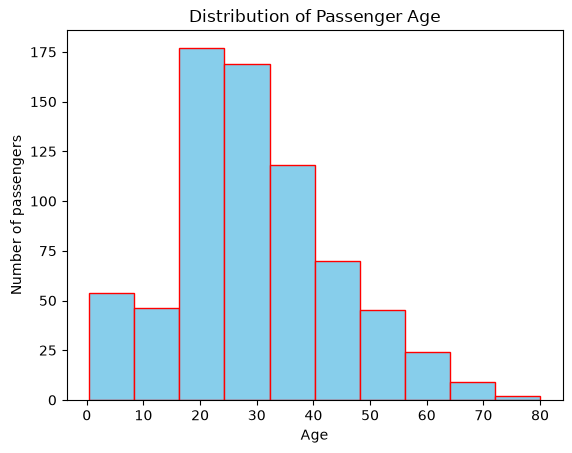

In [29]:
plt.hist(df["Age"], color='skyblue', edgecolor='red')
plt.xlabel('Age')
plt.ylabel('Number of passengers')
plt.title('Distribution of Passenger Age')
plt.show()

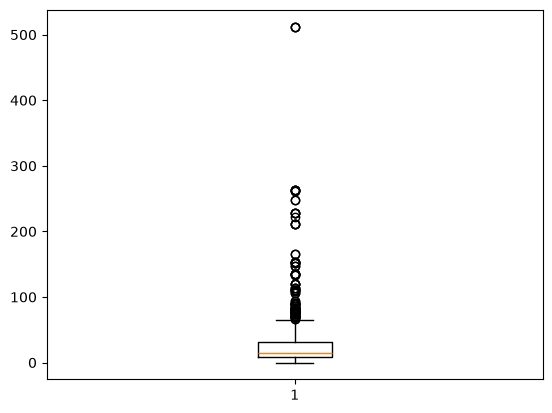

In [30]:
plt.boxplot(df["Fare"])
plt.show()

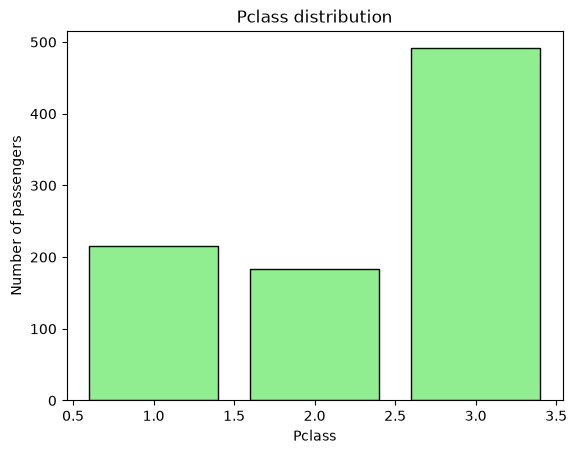

In [31]:
class_counts = df["Pclass"].value_counts().sort_index()
plt.bar(class_counts.index, class_counts.values, color = "lightgreen", edgecolor = 'black')
plt.xlabel("Pclass")
plt.ylabel("Number of passengers")
plt.title("Pclass distribution")
plt.show()

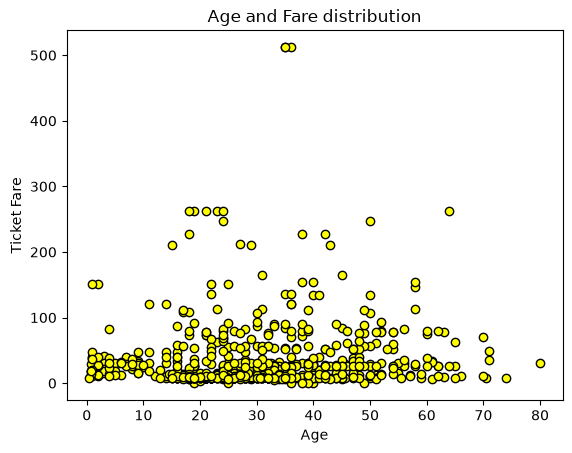

In [32]:
plt.scatter(df["Age"], df["Fare"], color = "yellow", edgecolor = "black")
plt.xlabel("Age")
plt.ylabel("Ticket Fare")
plt.title("Age and Fare distribution")
plt.show()

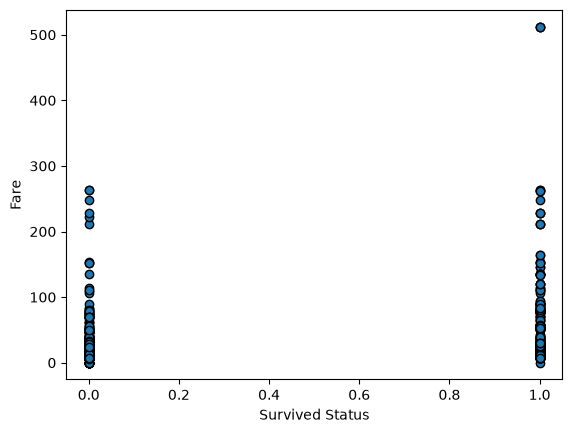

In [33]:
plt.scatter(df["Survived"], df["Fare"], edgecolor = "black")
plt.xlabel("Survived Status")
plt.ylabel("Fare")
plt.show()

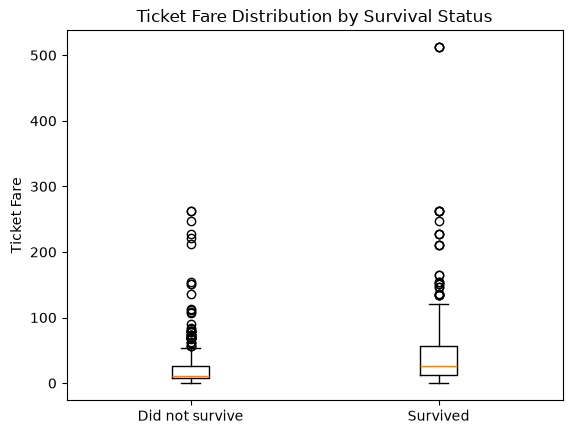

In [34]:
survived_fares = df[df["Survived"] == 1]["Fare"]
not_survived_fares = df[df["Survived"] == 0]["Fare"]

plt.boxplot([not_survived_fares, survived_fares],
            tick_labels=["Did not survive", "Survived"])

plt.ylabel("Ticket Fare")
plt.title("Ticket Fare Distribution by Survival Status")
plt.show()

In [40]:
print((df.groupby(
    "Pclass"
)["Survived"].mean()*100).round(2))

Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


#Question → Visualization → Observation → Further investigation → Evidence-based conclusion